<a href="https://colab.research.google.com/github/thanhsonnguyen-gif/ai-text-detection/blob/main/notebooks/E2_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E2 · Độ bền trước tấn công · Chủ: Người 1 · Phục vụ Chương 5 (mục 5.2, RQ1)
Dùng mô hình và **ngưỡng vận hành đã chốt ở E1** (không chọn lại ngưỡng trên dữ liệu bị tấn công: máy dò ngoài đời không biết trước mình sẽ bị tấn công).
- **T5.4 / F5.4**: TPR (và FPR nếu văn bản người cũng bị tấn công) theo 11 kiểu tấn công thật của RAID
- **F5.5**: tấn công tự cài theo cường độ (5% → 100% số từ)

In [ ]:
# === BOOTSTRAP: giữ nguyên ở đầu mọi notebook ===
OWNER = "Son&Tai"   # tên bạn
REPO  = "https://github.com/thanhsonnguyen-gif/ai-text-detection.git"

from google.colab import drive
drive.mount("/content/drive")
import os, sys, subprocess
if not os.path.exists("/content/repo"):
    url = REPO
    try:   # repo private: lưu Personal Access Token vào Colab Secrets với tên GH_TOKEN
        from google.colab import userdata
        url = REPO.replace("https://", f"https://{userdata.get('GH_TOKEN')}@")
    except Exception:
        pass
    subprocess.run(["git", "clone", "-q", url, "/content/repo"], check=True)
else:   # --ff-only + check=True: pull hỏng thì DỪNG, không âm thầm chạy tiếp với code cũ
    subprocess.run(["git", "-C", "/content/repo", "pull", "-q", "--ff-only"], check=True)
print("Code đang dùng:", subprocess.run(["git", "-C", "/content/repo", "log", "-1", "--format=%h %s (%cd)", "--date=short"],
                                        capture_output=True, text=True).stdout.strip())
for k in [k for k in sys.modules if k == "aitext" or k.startswith("aitext.")]:
    del sys.modules[k]   # chạy lại BOOTSTRAP ⇒ nạp lại aitext mới nhất, không dùng bản cũ còn trong bộ nhớ
if "/content/repo/src" not in sys.path:
    sys.path.insert(0, "/content/repo/src")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "/content/repo/requirements.txt"])

from aitext import config, spark_utils
spark_utils.ensure_pyspark()
spark = spark_utils.get_spark()
config.ensure_dirs()
import time, pandas as pd, matplotlib.pyplot as plt
from pyspark.sql import functions as F
print("Drive:", config.DRIVE_ROOT)

Mounted at /content/drive
Java 21 | PySpark 4.0.5
Drive: /content/drive/MyDrive/BigData_IE212_R11_VB2/AI-Text-Project


In [ ]:
from aitext import data, models, evaluate, textops
_, _, test = data.load_splits(spark)
m_base, m_def = models.load("lr_base"), models.load("lr_def")
th = models.load_thresholds(); print(th)
THR = {"baseline": th["thr_base"], "defended": th["thr_def"]}
MD  = {"baseline": (m_base, False), "defended": (m_def, True)}

{'reg_param': 1.0, 'thr_base': 0.7318487066775035, 'thr_def': 0.7309143970540265, 'fpr_target': 0.05}


## 1. 11 tấn công thật của RAID → T5.4, F5.4

,attack,n,TPR baseline,FPR baseline,TPR defended,FPR defended
0,none,15840,0.732,0.062,0.734,0.063
1,homoglyph,3285,0.599,0.583,0.736,0.082
2,number,3410,0.729,0.072,0.734,0.073
3,article_deletion,3255,0.726,0.061,0.728,0.063
4,insert_paragraphs,3344,0.728,0.073,0.731,0.073
5,perplexity_misspelling,3337,0.740,0.063,0.741,0.064
6,upper_lower,3341,0.726,0.057,0.728,0.057
7,whitespace,3375,0.744,0.059,0.746,0.059
8,zero_width_space,3299,0.840,0.826,0.737,0.061
9,synonym,3414,0.649,0.070,0.653,0.070


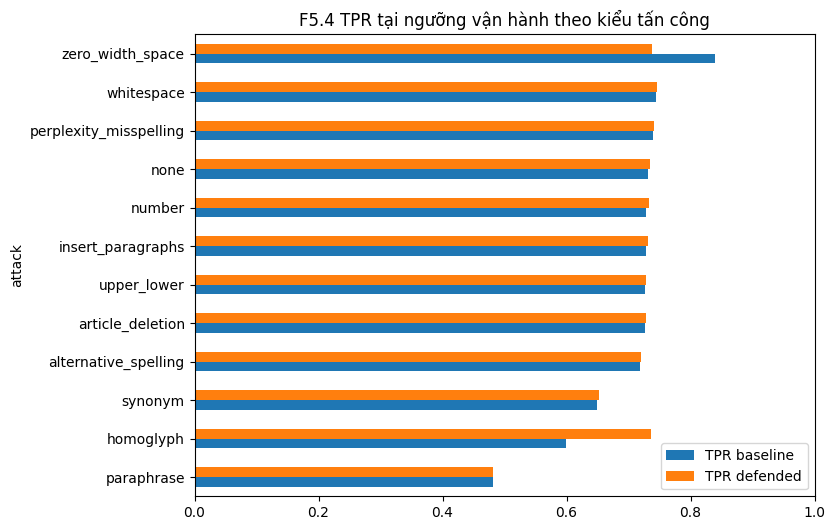

In [ ]:
rows = []
for atk in ["none"] + config.RAID_ATTACKS:
    d = test if atk == "none" else data.load_attacked(spark, atk)
    d = d.cache(); row = {"attack": atk, "n": d.count()}
    for name, (m, dfd) in MD.items():
        p = evaluate.score(m, d, models.text_col(dfd)).cache()
        row[f"TPR {name}"] = evaluate.rate_above(p, 1, THR[name])
        row[f"FPR {name}"] = evaluate.rate_above(p, 0, THR[name])
        evaluate.log_run("E2", OWNER, f"{name}|{atk}", {"tpr": row[f"TPR {name}"], "fpr": row[f"FPR {name}"], "threshold": THR[name], "n": row["n"]})
        p.unpersist()
    rows.append(row); d.unpersist()
t54 = pd.DataFrame(rows); display(t54.round(3))
evaluate.save_table(t54, "T5.4_raid_attacks")
fig, ax = plt.subplots(figsize=(8, 6))
t54.set_index("attack")[["TPR baseline", "TPR defended"]].sort_values("TPR baseline").plot.barh(ax=ax, xlim=(0, 1))
ax.set_title("F5.4 TPR tại ngưỡng vận hành theo kiểu tấn công"); evaluate.save_figure(fig, "F5.4_raid_attacks"); plt.show()

### 1b. AUROC theo kiểu tấn công → T5.4b

In [ ]:
rows = []
for atk in ["none"] + config.RAID_ATTACKS:
    d = test if atk == "none" else data.load_attacked(spark, atk)
    row = {"attack": atk}
    for name, (m, dfd) in MD.items():
        row[f"AUROC {name}"] = evaluate.auroc(evaluate.score(m, d, models.text_col(dfd)))
    rows.append(row)
t54b = pd.DataFrame(rows); display(t54b.round(3)); evaluate.save_table(t54b, "T5.4b_raid_attacks_auroc")

,attack,AUROC baseline,AUROC defended
0,none,0.913,0.913
1,homoglyph,0.508,0.907
2,number,0.910,0.910
3,article_deletion,0.909,0.909
4,insert_paragraphs,0.907,0.907
5,perplexity_misspelling,0.919,0.919
6,upper_lower,0.908,0.908
7,whitespace,0.915,0.915
8,zero_width_space,0.537,0.920
9,synonym,0.884,0.884


## 2. Tấn công tự cài theo cường độ → F5.5

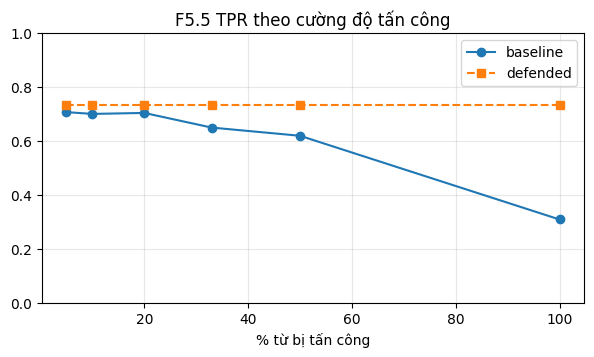

In [ ]:
g = F.col("generation"); rows = []
for rate in [20, 10, 5, 3, 2, 1]:
    col = F.when(F.col("label") == 1, textops.attack_both(g, rate)).otherwise(g)
    for name, (m, dfd) in MD.items():
        p = evaluate.score(m, test, textops.normalize(col) if dfd else col).cache()
        rows.append({"% từ bị tấn công": round(100 / rate), "mô hình": name, "TPR": evaluate.rate_above(p, 1, THR[name])})
        p.unpersist()
f55 = pd.DataFrame(rows); evaluate.save_table(f55, "F5.5_attack_strength")
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, sty in [("baseline", "o-"), ("defended", "s--")]:
    s = f55[f55["mô hình"] == name]; ax.plot(s["% từ bị tấn công"], s["TPR"], sty, label=name)
ax.set_ylim(0, 1); ax.set_xlabel("% từ bị tấn công"); ax.set_title("F5.5 TPR theo cường độ tấn công"); ax.legend(); ax.grid(alpha=.3)
evaluate.save_figure(fig, "F5.5_attack_strength"); plt.show()

## Ghi chú cho Chương 5: kiểu nào chuẩn hóa cứu được, kiểu nào không, vì sao
- ...